WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0.0386667561333211. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Spike counts before plasticity: <spikemonitor.count: array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
      dtype=int32)>
Plasticity step at 0.0 ms — 0 underactive neurons
Pruned 380 synapses at t=0 ms
Plasticity step at 1000.0 ms — 15 underactive neurons
Plasticity step at 2000.0 ms — 0 underactive neurons
Pruned 226 synapses at t=2500 ms
Plasticity step at 3000.0 ms — 0 underactive neurons
Plasticity step at 4000.0 ms — 1 underactive neurons
Plasticity step at 5000.0 ms — 3 underactive neurons
Pruned 226 synapses at t=5000 ms
Plasticity step at 6000.0 ms — 6 underactive neurons
Plasticity step at 7000.0 ms — 6 underactive neurons
Pruned 226 synapses at t=7500 ms
Plasticity step at 8000.0 ms — 7 underactive neurons
Plasticity step at 9000.0 ms — 7 underactive neurons
Plasticity step at 10000.0 ms — 7 underactive neurons
Pruned 226 synapses at t=10000 ms
Plasticity step at 11000.0 ms — 7 underactive neurons
Plasticity step at 12000.0 ms — 8 underactive neurons
Pruned

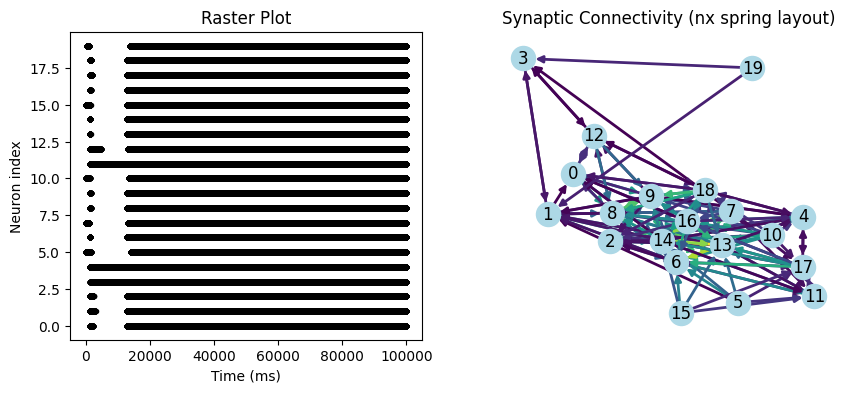

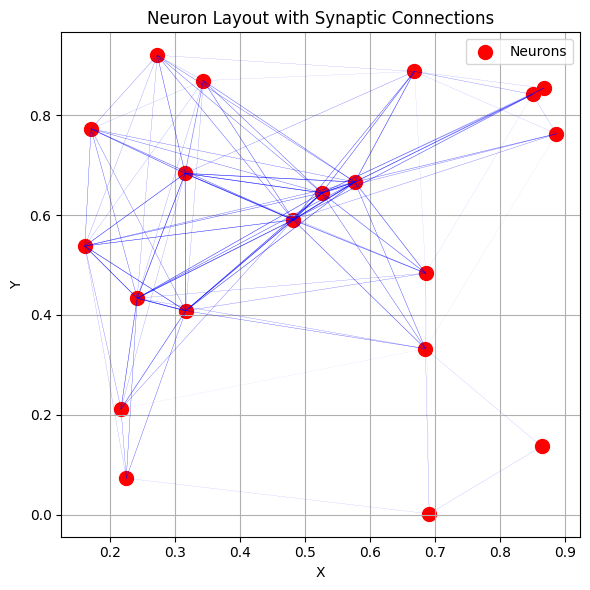

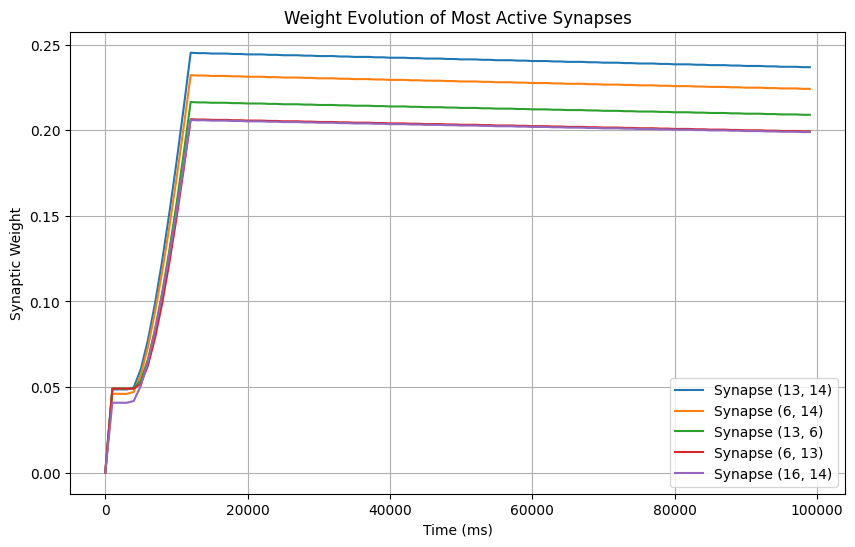

In [ ]:
from scipy.spatial.distance import cdist
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

start_scope()

# Neuron and simulation parameters
N = 20  # number of excitatory neurons
N_stim = 5
duration = 100*second
target_rate = 10*Hz
weight_trace = {}
times = []

neuron_positions = np.random.rand(N, 2)

def gaussian_weight(distance, sigma=0.3):
    return np.exp(-distance**2 / (2 * sigma**2))


# HH model equations
eqs = '''
dv/dt = (I_inj/area - gNa*m**3*h*(v - ENa) - gK*n**4*(v - EK) - gL*(v - EL)) / Cm : volt
dm/dt = alpham*(1 - m) - betam*m : 1
dn/dt = alphan*(1 - n) - betan*n : 1
dh/dt = alphah*(1 - h) - betah*h : 1
alpham = 0.1*(v/mV + 40)/(1 - exp(-(v/mV + 40)/10))/ms : Hz
betam = 4*exp(-(v/mV + 65)/18)/ms : Hz
alphah = 0.07*exp(-(v/mV + 65)/20)/ms : Hz
betah = 1/(1 + exp(-(v/mV + 35)/10))/ms : Hz
alphan = 0.01*(v/mV + 55)/(1 - exp(-(v/mV + 55)/10))/ms : Hz
betan = 0.125*exp(-(v/mV + 65)/80)/ms : Hz
I_inj : amp
'''

# Constants
Cm = 1*uF/cm**2
gNa = 120*msiemens/cm**2
gK = 36*msiemens/cm**2
gL = 0.3*msiemens/cm**2
ENa = 50*mV
EK = -77*mV
EL = -54.4*mV
area = 20000*umetre**2

# Neuron group
neurons = NeuronGroup(N, eqs, threshold='v > -20*mV', reset='v = -65*mV',
                      method='exponential_euler')
neurons.v = -65*mV
neurons.m = 0.05
neurons.h = 0.6
neurons.n = 0.32
neurons.I_inj = 0*nA

# Poisson input to N_stim random neurons
stim_indices = np.random.choice(N, size=N_stim, replace=False)
P_input = PoissonGroup(N_stim, rates=10*Hz)
S_input = Synapses(P_input, neurons, on_pre='I_inj_post += 1.5*nA')
S_input.connect(i=range(N_stim), j=stim_indices)

# Recurrent synapses (initially sparse, plastic)
S_rec = Synapses(neurons, neurons,
                 '''
                 w : 1
                 ''',
                 on_pre='I_inj_post += w*nA')
S_rec.connect(condition='i != j') 
S_rec.w=0.0

# Spike monitor
spikes = SpikeMonitor(neurons)
rate_monitor = PopulationRateMonitor(neurons)

# Homeostatic plasticity (updates every 1000 ms)
@network_operation(dt=1000*ms)
def homeostatic_plasticity():
    rates = spikes.count / defaultclock.t
    underactive = np.where(rates < target_rate)[0]
    print(f"Plasticity step at {defaultclock.t/ms:.1f} ms — {len(underactive)} underactive neurons")

    for u in underactive:
        pos_u = neuron_positions[u]

        for pre in range(N):  # Excitatory only
            if pre == u:
                continue

            dist = np.linalg.norm(neuron_positions[pre] - pos_u)
            if dist > 0.5:
                continue

            scale = gaussian_weight(dist)
            delta = (target_rate - rates[u]) / target_rate


            S_rec.w[pre, u] = clip(S_rec.w[pre, u] + delta * 0.05 * scale, 0, 1.0)




@network_operation(dt=2500*ms)
def weight_decay():
    decay_rate = 0.001  # percent decay per second
    S_rec.w[:] *= (1 - decay_rate)
    prune_threshold = 0.0001
    S_rec.w[S_rec.w < prune_threshold] = 0
    num_pruned = np.sum(S_rec.w[:] < prune_threshold)
    print(f"Pruned {num_pruned} synapses at t={defaultclock.t/ms:.0f} ms")

@network_operation(dt=1000*ms)
def record_weights():
    times.append(defaultclock.t/ms)
    
    # Record the weight of each synapse
    for i in range(N):
        for j in range(N):
            if i != j:
                weight = S_rec.w[i, j]
                if (i, j) not in weight_trace:
                    weight_trace[(i, j)] = []
                weight_trace[(i, j)].append(weight)



print(f"Spike counts before plasticity: {spikes.count}")
run(duration)
print(f"Spike counts after run: {spikes.count}")

# 1. Raster plot
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.title("Raster Plot")
plt.plot(spikes.t/ms, spikes.i, '.k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')

# 2. Synaptic connectivity graph
print(f"Number of synapses: {len(S_rec.i[:])}")
plt.subplot(122)
plt.title("Synaptic Connectivity (nx spring layout)")
G = nx.DiGraph()
G.add_nodes_from(range(N))
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        G.add_edge(int(src), int(tgt), weight=w)
if G.number_of_edges() == 0:
    print("Warning: Graph has no edges.")
else:
    pos = nx.spring_layout(G)
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    nx.draw(G, pos, with_labels=True, node_color='lightblue',
            edge_color=weights, edge_cmap=plt.cm.viridis,
            width=2, arrowsize=10)
    plt.show()

# 3. Neuron layout with connection lines based on weights
plt.figure(figsize=(6, 6))
plt.title("Neuron Layout with Synaptic Connections")
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    pos_src = neuron_positions[src]
    pos_tgt = neuron_positions[tgt]
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        plt.plot([pos_src[0], pos_tgt[0]], [pos_src[1], pos_tgt[1]],
                 alpha=0.6, linewidth=w*3, color='blue')
plt.scatter(neuron_positions[:, 0], neuron_positions[:, 1], c='red', s=100, label='Neurons')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Weight evolution of most active synapses
def find_most_active_synapses(weight_trace):
    weight_changes = {}
    for (i, j), weights in weight_trace.items():
        weight_changes[(i, j)] = max(weights) - min(weights)
    most_active = sorted(weight_changes.items(), key=lambda item: item[1], reverse=True)
    return [synapse for synapse, _ in most_active[:5]]

top_synapses = find_most_active_synapses(weight_trace)

plt.figure(figsize=(10, 6))
for synapse in top_synapses:
    synaptic_weight = weight_trace[synapse]
    plt.plot(times, synaptic_weight, label=f'Synapse ({synapse[0]}, {synapse[1]})')
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic Weight')
plt.title('Weight Evolution of Most Active Synapses')
plt.legend()
plt.grid(True)
plt.show()



Spike counts before plasticity: <spikemonitor_2.count: array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
      dtype=int32)>
Spike counts after run: <spikemonitor_2.count: array([17599, 13464, 15028, 16313, 17508, 17526, 16131, 15954, 14922,
       13559, 19875, 19984, 13530, 17378, 18786, 17771, 16042, 13488,
       19036, 14774], dtype=int32)>
Number of synapses: 380


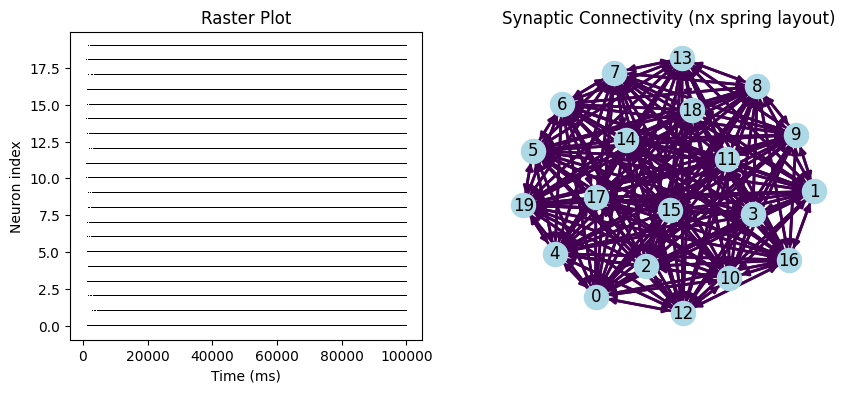

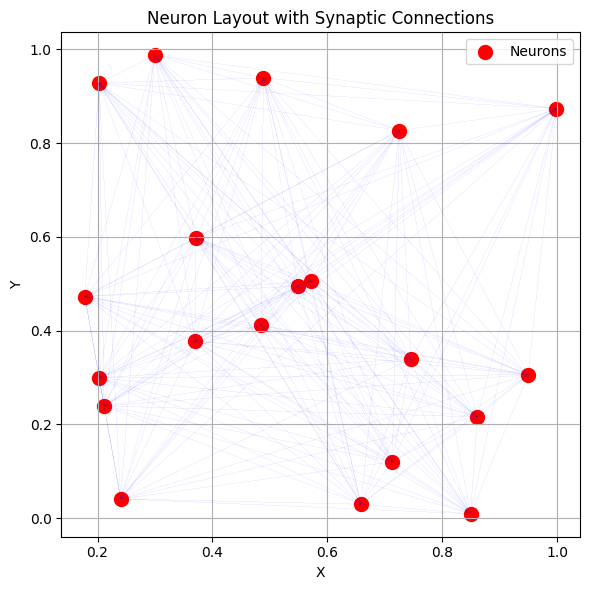

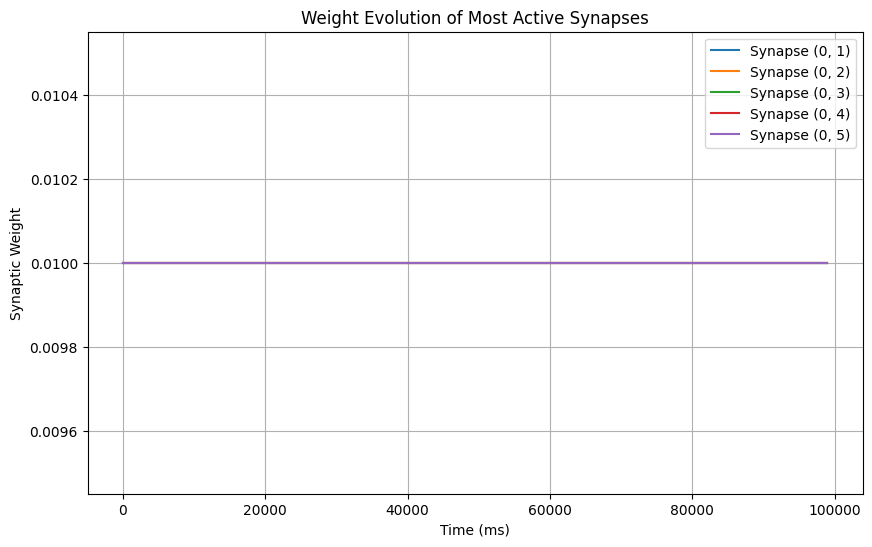

In [33]:
from scipy.spatial.distance import cdist
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

start_scope()

# Neuron and simulation parameters
N = 20  # number of excitatory neurons
duration = 100*second
weight_trace = {}
times = []
target_rate = 5*Hz
Stim_rate = 5*Hz
learning_rate = 0.001 #HS


neuron_positions = np.random.rand(N, 2)

def gaussian_weight(distance, sigma=0.3):
    distance = np.abs(np.real(distance))
    arg = -distance**2 / (2 * sigma**2)
    arg = np.clip(arg, -700, 0)  # Avoid overflow in exp
    return np.exp(arg)

# Constants
Cm = 0.2*uF
gNa = 120*nsiemens
gK = 360*nsiemens
gL = 10.0*nsiemens
ENa = 50*mV
EK = -77*mV
EL = -70*mV
t_on = 5000.0*ms
t_off = 50000*ms
I_bg = -2.0*nA

# HH model equations
eqs = '''
dv/dt = (I_total - gNa*m**3*h*(v - ENa) - gK*n**4*(v - EK) - gL*(v - EL)) / Cm : volt
I_total = I_syn + I_bg_dyn : amp
I_syn : amp
I_bg_dyn = int(t >= t_on and t < t_off) * I_bg : amp (shared)
dm/dt = alpham*(1 - m) - betam*m : 1
dn/dt = alphan*(1 - n) - betan*n : 1
dh/dt = alphah*(1 - h) - betah*h : 1
alpham = 0.1*(v/mV + 40)/(1 - exp(-(v/mV + 40)/10))/ms : Hz
betam = 4*exp(-(v/mV + 65)/18)/ms : Hz
alphah = 0.07*exp(-(v/mV + 65)/20)/ms : Hz
betah = 1/(1 + exp(-(v/mV + 35)/10))/ms : Hz
alphan = 0.01*(v/mV + 55)/(1 - exp(-(v/mV + 55)/10))/ms : Hz
betan = 0.125*exp(-(v/mV + 65)/80)/ms : Hz
'''
#I_inj = -I_bg / (1 + exp((t - t_off) / (5*second))) : amp (shared)


# Neuron group
neurons = NeuronGroup(N, eqs, threshold='v > -20*mV', reset='v = -65*mV',
                      method='exponential_euler')
neurons.v = -65*mV
neurons.m = 0.05
neurons.h = 0.6
neurons.n = 0.32
neurons.I_syn = 0.2*nA

# Poisson input to N_stim random neurons
P_input = PoissonGroup(N, rates=Stim_rate)  
S_input = Synapses(P_input, neurons, on_pre='I_syn_post += 0.5*nA')
S_input.connect(condition='i != j',p=0.3)
#S_input.connect(j='i')  

# Recurrent synapses (initially sparse, plastic)
S_rec = Synapses(neurons, neurons,
                 '''
                 w : 1
                 ''',
                 on_pre='I_syn_post += w*nA')
S_rec.connect(condition='i != j') 
S_rec.w=0.01

# Spike monitor
spikes = SpikeMonitor(neurons)
rate_monitor = PopulationRateMonitor(neurons)

# Homeostatic plasticity (updates every 1000 ms)
# @network_operation(dt=1000*ms)
# def homeostatic_plasticity():
#     if defaultclock.t == 0*ms:
#         return      
#     rates = spikes.count / defaultclock.t
#     print(f"Plasticity step at {defaultclock.t/ms:.1f} ms")
#     for post in range(N):
#         rate_post = rates[post]
#         pos_post = neuron_positions[post]
#         for pre in range(N):
#             if pre == post:
#                 continue
#             dist = np.linalg.norm(neuron_positions[pre] - pos_post)
#             dist = float(np.abs(np.real(dist)))
#             if dist > 0.5:
#                 continue
#             scale = gaussian_weight(dist)
#             if np.isnan(scale):
#                 print(f"NaN in scale: dist={dist}")
#             delta = np.clip((target_rate - rate_post) / target_rate, -1.0, 1.0)
#             if np.isnan(delta):
#                 print(f"NaN in delta: rate_post={rate_post}, target_rate={target_rate}")
#             new_weight = S_rec.w[pre, post] + delta * learning_rate * scale
#             new_weight = clip(new_weight, 0.001, 0.2)
#             if np.isnan(new_weight):
#                 print(f"NaN in new weight for synapse ({pre}->{post}): "
#                       f"w={S_rec.w[pre, post]}, delta={delta}, scale={scale}")            
#             S_rec.w[pre, post] = new_weight
#     print(f"Weight range: min={np.min(S_rec.w[:])}, max={np.max(S_rec.w[:])}")

# window = 1*second
# @network_operation(dt=1000*ms)
# def homeostatic_plasticity():
#     if defaultclock.t < window:
#         return  # not enough time yet    
#     t0 = defaultclock.t - window
#     # grab arrays of all spike times and neuron indices
#     all_t  = spikes.t
#     all_i  = spikes.i
#     # pre-allocate rate vector
#     rates = np.zeros(N) * Hz
#     for post in range(N):
#         # boolean mask of spikes by this neuron in [t0, now)
#         recent_mask = np.logical_and(all_i == post,
#                                      all_t >= t0)
#         count_last = np.sum(recent_mask)
#         rates[post] = count_last / window
#     print(f"Plasticity at {defaultclock.t/ms:.0f} ms, recent rates: {rates}")    
#     for post in range(N):
#         rate_post = rates[post]
#         pos_post = neuron_positions[post]

#         for pre in range(N):
#             if pre == post:
#                 continue
#             dist = np.linalg.norm(neuron_positions[pre] - pos_post)
#             if dist > 0.5:
#                 continue
#             scale = gaussian_weight(dist)
#             delta = np.clip((target_rate - rate_post) / target_rate, -1.0, 1.0)
#             new_w = S_rec.w[pre, post] + learning_rate * scale * delta
#             S_rec.w[pre, post] = clip(new_w, 0.001, 1)
#     print(f"Weight range: {np.min(S_rec.w[:]):.4f} - {np.max(S_rec.w[:]):.4f}")


# @network_operation(dt=2500*ms)
# def weight_decay():
#     decay_rate = 0.001  # percent decay per second
#     S_rec.w[:] *= (1 - decay_rate)
#     prune_threshold = 0.0001
#     S_rec.w[S_rec.w < prune_threshold] = 0
#     num_pruned = np.sum(S_rec.w[:] < prune_threshold)
#     print(f"Pruned {num_pruned} synapses at t={defaultclock.t/ms:.0f} ms")

@network_operation(dt=1000*ms)
def record_weights():
    times.append(defaultclock.t/ms)
    
    # Record the weight of each synapse
    for i in range(N):
        for j in range(N):
            if i != j:
                weight = S_rec.w[i, j]
                if (i, j) not in weight_trace:
                    weight_trace[(i, j)] = []
                weight_trace[(i, j)].append(weight)



print(f"Spike counts before plasticity: {spikes.count}")
run(duration)
print(f"Spike counts after run: {spikes.count}")



# 1. Raster plot
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.title("Raster Plot")
plt.plot(spikes.t/ms, spikes.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')

# 2. Synaptic connectivity graph
print(f"Number of synapses: {len(S_rec.i[:])}")
plt.subplot(122)
plt.title("Synaptic Connectivity (nx spring layout)")
G = nx.DiGraph()
G.add_nodes_from(range(N))
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        G.add_edge(int(src), int(tgt), weight=w)
if G.number_of_edges() == 0:
    print("Warning: Graph has no edges.")
else:
    pos = nx.spring_layout(G)
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    nx.draw(G, pos, with_labels=True, node_color='lightblue',
            edge_color=weights, edge_cmap=plt.cm.viridis,
            width=2, arrowsize=10)
    plt.show()

# 3. Neuron layout with connection lines based on weights
plt.figure(figsize=(6, 6))
plt.title("Neuron Layout with Synaptic Connections")
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    pos_src = neuron_positions[src]
    pos_tgt = neuron_positions[tgt]
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        plt.plot([pos_src[0], pos_tgt[0]], [pos_src[1], pos_tgt[1]],
                 alpha=0.6, linewidth=w*3, color='blue')
plt.scatter(neuron_positions[:, 0], neuron_positions[:, 1], c='red', s=100, label='Neurons')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Weight evolution of most active synapses
def find_most_active_synapses(weight_trace):
    weight_changes = {}
    for (i, j), weights in weight_trace.items():
        weight_changes[(i, j)] = max(weights) - min(weights)
    most_active = sorted(weight_changes.items(), key=lambda item: item[1], reverse=True)
    return [synapse for synapse, _ in most_active[:5]]

top_synapses = find_most_active_synapses(weight_trace)

plt.figure(figsize=(10, 6))
for synapse in top_synapses:
    synaptic_weight = weight_trace[synapse]
    plt.plot(times, synaptic_weight, label=f'Synapse ({synapse[0]}, {synapse[1]})')
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic Weight')
plt.title('Weight Evolution of Most Active Synapses')
plt.legend()
plt.grid(True)
plt.show()




In [26]:
S_rec.w[:]

array([0.001, 0.001, 0.001, 0.   , 0.   , 0.001, 0.001, 0.   , 0.001,
       0.001, 0.001, 0.001, 0.001, 0.001, 0.   , 0.   , 0.001, 0.001,
       0.   , 0.001, 0.   , 0.   , 0.   , 0.001, 0.001, 0.001, 0.   ,
       0.   , 0.001, 0.001, 0.   , 0.001, 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.001, 0.   , 0.001, 0.   , 0.   , 0.   , 0.001,
       0.001, 0.001, 0.   , 0.001, 0.001, 0.   , 0.001, 0.   , 0.   ,
       0.001, 0.001, 0.001, 0.001, 0.   , 0.001, 0.   , 0.   , 0.   ,
       0.   , 0.001, 0.001, 0.   , 0.001, 0.001, 0.   , 0.001, 0.   ,
       0.001, 0.001, 0.001, 0.001, 0.   , 0.   , 0.   , 0.   , 0.001,
       0.   , 0.   , 0.   , 0.   , 0.001, 0.001, 0.   , 0.   , 0.   ,
       0.001, 0.001, 0.   , 0.   , 0.   , 0.   , 0.001, 0.   , 0.   ,
       0.001, 0.   , 0.   , 0.   , 0.   , 0.001, 0.001, 0.001, 0.   ,
       0.   , 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.   ,
       0.   , 0.   , 0.   , 0.001, 0.   , 0.   , 0.001, 0.   , 0.   ,
       0.001, 0.   ,

[Text(0, 0.5, 'Neuron index'), Text(0.5, 0, 'time (ms)')]

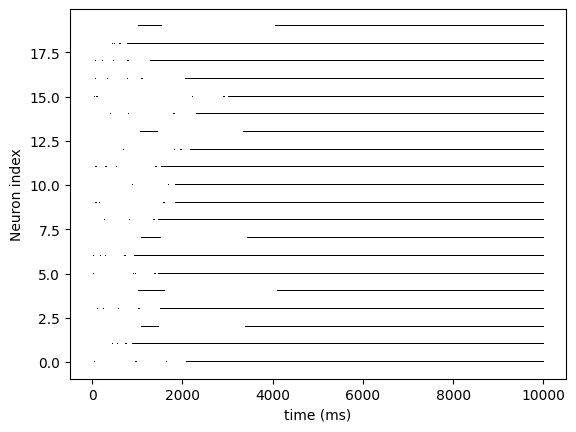

In [15]:
fig, ax = plt.subplots()
ax.plot(spikes.t/ms, spikes.i, ',k')
ax.set(ylabel='Neuron index', xlabel='time (ms)')

Plasticity step at 1000.0 ms
Exc weight range: 0. S to 10. pS
Plasticity step at 2000.0 ms
Exc weight range: 0. S to 0. S
Plasticity step at 3000.0 ms
Exc weight range: 0. S to 0. S
Plasticity step at 4000.0 ms
Exc weight range: 0. S to 0. S
Plasticity step at 5000.0 ms
Exc weight range: 0. S to 0. S
Plasticity step at 6000.0 ms
Exc weight range: 0. S to 0. S
Plasticity step at 7000.0 ms
Exc weight range: 0. S to 0. S
Plasticity step at 8000.0 ms
Exc weight range: 0. S to 0. S
Plasticity step at 9000.0 ms
Exc weight range: 0. S to 0. S


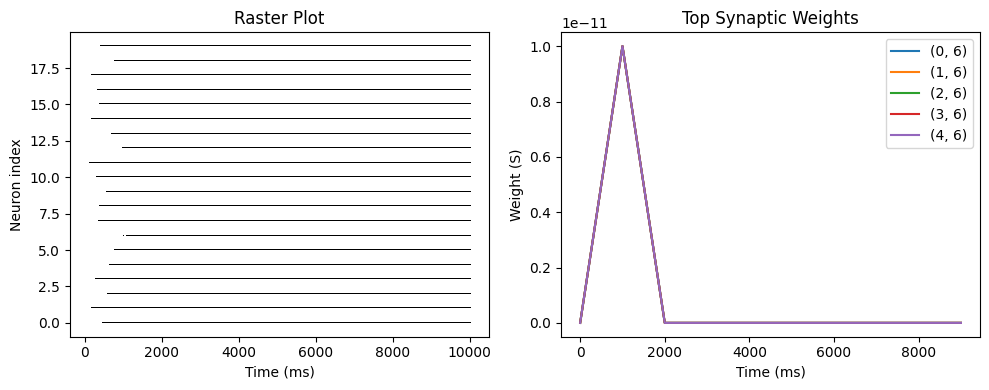

In [ ]:
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt

start_scope()

# Parameters
N_exc = 20
N_inh = 5
N_total = N_exc + N_inh
duration = 10*second

# Neuron parameters
C_m = 200*pF
g_l = 10*nS
E_l = -70*mV
E_e = 0*mV
E_i = -80*mV
tau_e = 5*ms
tau_i = 10*ms
v_thresh = -50*mV
v_reset = -65*mV
refractory_period = 5*ms

# Alcohol effect
alcohol_reduction_exc = 0.5  # 50% less excitatory effect
alcohol_increase_inh = 1.5   # 50% more inhibitory effect

# Neuron model
neuron_eqs = '''
dv/dt = (g_l*(E_l-v) + g_e*(E_e-v) + g_i*(E_i-v) + I_ex)/C_m : volt (unless refractory)
dg_e/dt = -g_e/tau_e : siemens
dg_i/dt = -g_i/tau_i : siemens
I_ex : amp
'''

# Neuron groups
neurons = NeuronGroup(N_total, neuron_eqs,
                      threshold='v>v_thresh', reset='v=v_reset',
                      refractory=refractory_period, method='euler')

exc_neurons = neurons[:N_exc]
inh_neurons = neurons[N_exc:]

neurons.v = E_l
neurons.I_ex = 0*nA

# Poisson input to excitatory neurons
poisson = PoissonGroup(N_exc, rates=5*Hz)
stim = Synapses(poisson, exc_neurons, on_pre='I_ex_post += 100*pA')
stim.connect(j='i')

# Synaptic models
synapses_eqs = '''
w : siemens
'''

# Excitatory to all neurons
exc_syn = Synapses(exc_neurons, neurons, model=synapses_eqs,
                   on_pre='g_e_post += alcohol_reduction_exc * w')
exc_syn.connect(condition='i != j')
exc_syn.w = 0*nS  # start from zero

# Inhibitory to all neurons
inh_syn = Synapses(inh_neurons, neurons, model=synapses_eqs,
                   on_pre='g_i_post += alcohol_increase_inh * w')
inh_syn.connect(condition='i != j')
inh_syn.w = 2*nS  # fixed inhibition

# Monitors
spikes = SpikeMonitor(neurons)
rate_monitor = PopulationRateMonitor(neurons)
weight_trace = {}
times = []

@network_operation(dt=1000*ms)
def homeostatic_plasticity():
    if defaultclock.t == 0*ms:
        return
    
    rates = spikes.count / defaultclock.t
    print(f"Plasticity step at {defaultclock.t/ms:.1f} ms")
    
    for post in range(N_total):
        if post >= N_exc:
            continue  # Skip inhibitory neurons
        
        rate_post = rates[post]
        delta = np.clip((target_rate - rate_post) / target_rate, -1.0, 1.0)
        
        for pre in range(N_exc):
            if pre == post:
                continue
            current_weight = exc_syn.w[pre, post]
            new_weight = clip(current_weight + delta * learning_rate * nS, 0*nS, 5*nS)
            exc_syn.w[pre, post] = new_weight

    print(f"Exc weight range: {np.min(exc_syn.w[:])} to {np.max(exc_syn.w[:])}")

@network_operation(dt=1000*ms)
def record_weights():
    times.append(defaultclock.t/ms)
    for i in range(N_exc):
        for j in range(N_total):
            if i != j:
                w = exc_syn.w[i, j]
                if (i, j) not in weight_trace:
                    weight_trace[(i, j)] = []
                weight_trace[(i, j)].append(w)

run(duration)

# Plotting
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.title("Raster Plot")
plt.plot(spikes.t/ms, spikes.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')

# Weight evolution of top synapses
def find_most_active_synapses(trace_dict):
    changes = {k: max(w) - min(w) for k, w in trace_dict.items()}
    return sorted(changes, key=changes.get, reverse=True)[:5]

top_synapses = find_most_active_synapses(weight_trace)

plt.subplot(122)
for syn in top_synapses:
    plt.plot(times, weight_trace[syn], label=f"{syn}")
plt.xlabel('Time (ms)')
plt.ylabel('Weight (S)')
plt.legend()
plt.title('Top Synaptic Weights')
plt.tight_layout()
plt.show()


Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=100. fS
Weight range: min=0. S, max=

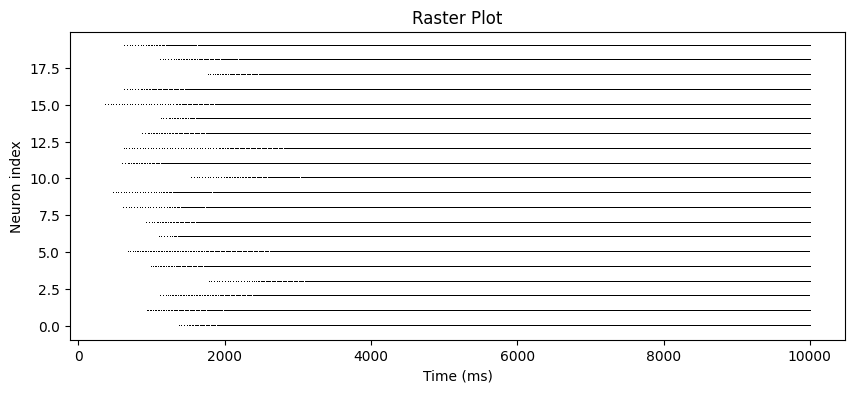

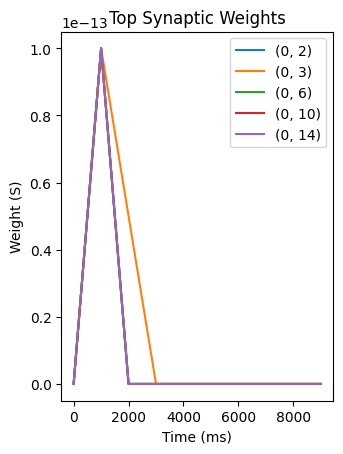

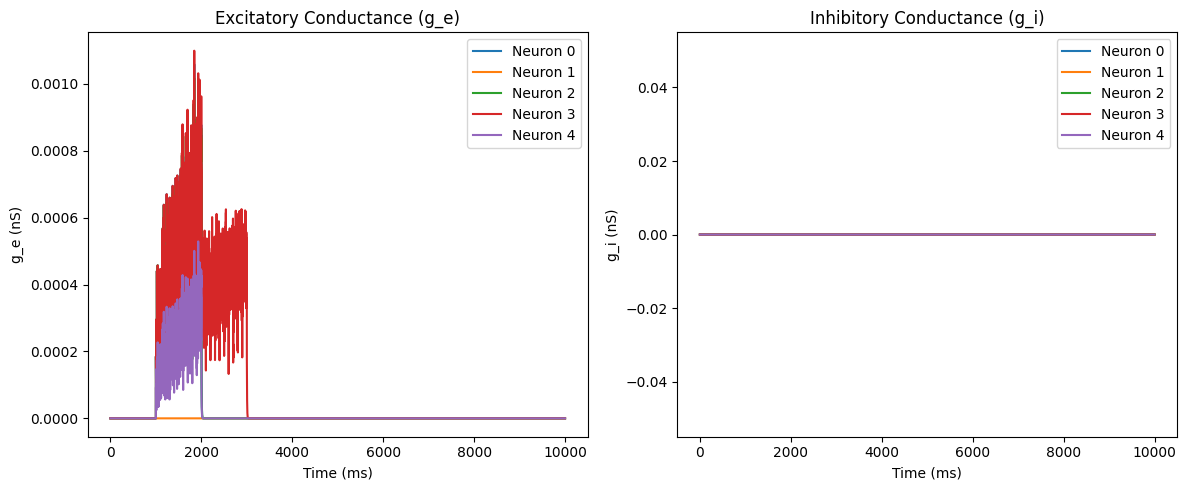

In [1]:
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt

start_scope()

# Parameters
N_exc = 20
N_inh = 5
runtime = 10*second
weight_trace = {}
times = []

# Neuron model parameters
C_m = 200*pF
g_l = 10*nS
E_l = -70*mV
E_e = 0*mV
E_i = -80*mV
tau_e = 5*ms
tau_i = 10*ms


# Alcohol effect parameters
alcohol_start = 1*second
alcohol_end = 5*second
exc_alcohol_factor = 0.5
inh_alcohol_factor = 1.5

# Neuron model
eqs = '''
dv/dt = (g_l*(E_l-v) + g_e*(E_e-v) + g_i*(E_i-v) + I_ex)/C_m : volt (unless refractory)
dg_e/dt = -g_e/tau_e : siemens
dg_i/dt = -g_i/tau_i : siemens
I_ex : amp
'''

neurons = NeuronGroup(N_exc + N_inh, eqs, threshold='v>-20*mV', reset='v=-60*mV', refractory=5*ms, method='euler')
neurons.v = E_l
neurons.I_ex = 0*amp


exc_neurons = neurons[:N_exc]
inh_neurons = neurons[N_exc:]

# Poisson input to excitatory neurons
poisson_input = PoissonGroup(N_exc, rates=3*Hz)
poisson_syn = Synapses(poisson_input, exc_neurons, on_pre='I_ex_post += 200*pA')
poisson_syn.connect(j='i')

# Excitatory to excitatory
exc_exc = Synapses(exc_neurons, exc_neurons, on_pre='g_e_post += w_e', model='w_e : siemens')
exc_exc.connect(condition='i != j')
exc_exc.w_e = 0.0*nS

# Excitatory to inhibitory
exc_inh = Synapses(exc_neurons, inh_neurons, on_pre='g_e_post += w_e', model='w_e : siemens')
exc_inh.connect(p=0.9)  
exc_inh.w_e = 0.01*nS

# Inhibitory to excitatory
inh_exc = Synapses(inh_neurons, exc_neurons, on_pre='g_i_post += w_i', model='w_i : siemens')
inh_exc.connect(p=0.9)  
inh_exc.w_i = 1.0*nS

# monitors
spike_mon = SpikeMonitor(neurons)
rate_mon = PopulationRateMonitor(neurons)
conductance_mon = StateMonitor(neurons, ['g_e', 'g_i'], record=True)  # or record=[0, 1, 2] for specific neurons


# Homeostatic plasticity
@network_operation(dt=1000*ms)
def homeostatic_plasticity():
    if defaultclock.t == 0*ms:
        return
    rates = spike_mon.count / defaultclock.t
    target_rate = 2*Hz
    eta = 0.0001
    gmax_e=0.001
    for post in range(N_exc):
        rate_post = rates[post]
        for pre in range(N_exc):
            if pre == post:
                continue
            delta = np.clip((target_rate - rate_post) / target_rate, -1.0, 1.0)
            new_w = exc_exc.w_e[pre, post] + eta * delta * nS
            exc_exc.w_e[pre, post] = clip(new_w, 0*nS, gmax_e*nS)
        print(f"Weight range: min={np.min(exc_exc.w_e[:])}, max={np.max(exc_exc.w_e[:])}")



# Alcohol modulation
@network_operation(dt=100*ms)
def apply_alcohol():
    t = defaultclock.t
    if alcohol_start <= t < alcohol_end:
        exc_neurons.g_e *= exc_alcohol_factor
        exc_neurons.g_i *= inh_alcohol_factor

@network_operation(dt=1000*ms)
def record_weights():
    times.append(defaultclock.t/ms)
    for i in range(N_exc):
        for j in range(N_exc):
            if i != j:
                w = exc_exc.w_e[i, j]
                if (i, j) not in weight_trace:
                    weight_trace[(i, j)] = []
                weight_trace[(i, j)].append(w)
                
run(runtime)

# Plot
plt.figure(figsize=(10, 4))
plt.title("Raster Plot")
plt.plot(spike_mon.t/ms, spike_mon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.show()

# Weight evolution of top synapses
def find_most_active_synapses(trace_dict):
    changes = {k: max(w) - min(w) for k, w in trace_dict.items()}
    return sorted(changes, key=changes.get, reverse=True)[:5]

top_synapses = find_most_active_synapses(weight_trace)

plt.subplot(122)
for syn in top_synapses:
    plt.plot(times, weight_trace[syn], label=f"{syn}")
plt.xlabel('Time (ms)')
plt.ylabel('Weight (S)')
plt.legend()
plt.title('Top Synaptic Weights')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))

# Plot g_e
plt.subplot(1, 2, 1)
plt.title('Excitatory Conductance (g_e)')
for i in range(5):  
    plt.plot(conductance_mon.t / ms, conductance_mon.g_e[i] / nS, label=f'Neuron {i}')
plt.xlabel('Time (ms)')
plt.ylabel('g_e (nS)')
plt.legend()

# Plot g_i
plt.subplot(1, 2, 2)
plt.title('Inhibitory Conductance (g_i)')
for i in range(5):
    plt.plot(conductance_mon.t / ms, conductance_mon.g_i[i] / nS, label=f'Neuron {i}')
plt.xlabel('Time (ms)')
plt.ylabel('g_i (nS)')
plt.legend()

plt.tight_layout()
plt.show()

